# Employee Attrition Prediction Using CART



## 1. Import libraries
I am importing the libraries needed to read the CSV file, create graphs, build the CART model and evaluate its results.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report



## 2. Load the CSV dataset
Loading the dataset

In [2]:
df = pd.read_csv("employee_attrition_dataset.csv")
print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully
Dataset shape: (1200, 16)


,EmployeeID,Age,Department,JobRole,MonthlyIncome,YearsAtCompany,YearsInCurrentRole,JobSatisfaction,WorkLifeBalance,OverTime,DistanceFromHome,BusinessTravel,TrainingTimesLastYear,Education,PerformanceRating,Attrition
0,EMP1001,38,Finance,Financial Analyst,3811,12,8,2,1,No,30,Travel_Rarely,3,5,3,No
1,EMP1002,45,Research & Development,Laboratory Technician,6500,16,12,4,3,Yes,21,Travel_Rarely,4,4,4,No
2,EMP1003,27,IT,IT Manager,4166,2,1,2,1,No,7,Travel_Rarely,2,5,3,No
3,EMP1004,45,Human Resources,HR Manager,8713,21,8,4,1,No,8,Travel_Rarely,0,3,3,No
4,EMP1005,57,Sales,Sales Representative,7502,18,7,4,3,Yes,3,Travel_Rarely,5,3,3,No


## 3. Understand the dataset
I am checking the columns, data types and missing values before training the model.

In [3]:
print(df.columns.tolist())
print("\\nDataset information:")
df.info()
print("\\nMissing values:")
print(df.isnull().sum())

['EmployeeID', 'Age', 'Department', 'JobRole', 'MonthlyIncome', 'YearsAtCompany', 'YearsInCurrentRole', 'JobSatisfaction', 'WorkLifeBalance', 'OverTime', 'DistanceFromHome', 'BusinessTravel', 'TrainingTimesLastYear', 'Education', 'PerformanceRating', 'Attrition']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   EmployeeID             1200 non-null   object
 1   Age                    1200 non-null   int64 
 2   Department             1200 non-null   object
 3   JobRole                1200 non-null   object
 4   MonthlyIncome          1200 non-null   int64 
 5   YearsAtCompany         1200 non-null   int64 
 6   YearsInCurrentRole     1200 non-null   int64 
 7   JobSatisfaction        1200 non-null   int64 
 8   WorkLifeBalance        1200 non-null   int64 
 9   OverTime               1200 non-null   o

## 4. Check employee attrition
I am checking how many employees stayed and how many left.

Attrition
No     998
Yes    202
Name: count, dtype: int64


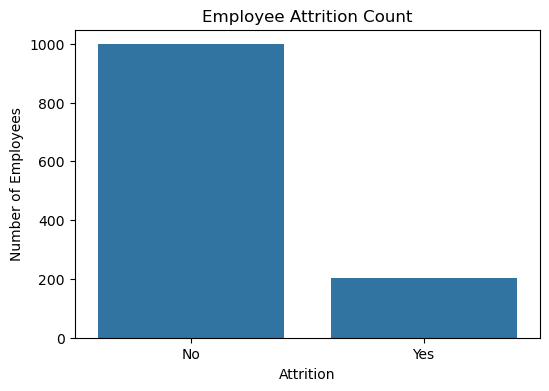

In [4]:
print(df["Attrition"].value_counts())
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Count")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

## 5. Explore employee details
These charts compare attrition across departments and overtime groups.

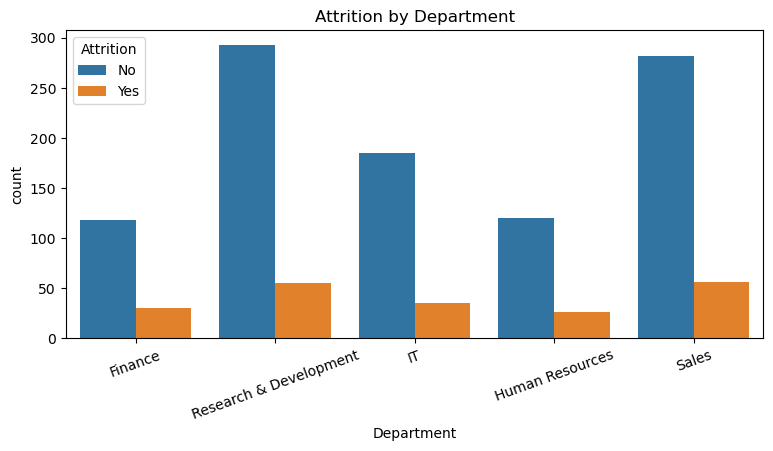

In [5]:
plt.figure(figsize=(9, 4))
sns.countplot(data=df, x="Department", hue="Attrition")
plt.title("Attrition by Department")
plt.xticks(rotation=20)
plt.show()

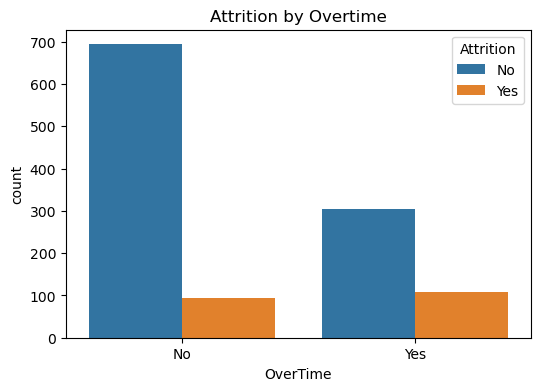

In [6]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="OverTime", hue="Attrition")
plt.title("Attrition by Overtime")
plt.show()

## 6. Select input and output columns
I am removing EmployeeID because it is only an identification number. The remaining columns are inputs, and Attrition is the output.

In [7]:
X = df.drop(columns=["EmployeeID", "Attrition"])
y = df["Attrition"]
print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (1200, 14)
Output shape: (1200,)


## 7. Identify numerical and categorical columns
Numerical columns contain numbers such as age and income. Categorical columns contain text such as department and job role.

In [8]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Age', 'MonthlyIncome', 'YearsAtCompany', 'YearsInCurrentRole', 'JobSatisfaction', 'WorkLifeBalance', 'DistanceFromHome', 'TrainingTimesLastYear', 'Education', 'PerformanceRating']
Categorical features: ['Department', 'JobRole', 'OverTime', 'BusinessTravel']


## 8. Split the dataset
I am using 80% of the records for training and 20% for testing. Stratify keeps the target proportions similar in both sets.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 960
Testing records: 240


## 9. Prepare the data
I am filling missing numerical values with the median and categorical values with the most common value. One-Hot Encoding converts text categories into numeric columns.

In [10]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

## 10. Implement CART
CART means Classification and Regression Tree. This is a classification task because the result is Yes or No. I am using Gini impurity to choose the splits. The maximum depth is limited to make the tree easier to read.

In [11]:
cart_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        min_samples_split=20,
        class_weight="balanced",
        random_state=42
    ))
])
cart_model.fit(X_train, y_train)
print("CART model training completed.")

CART model training completed.


## 11. Make predictions
I am using the trained model to predict attrition for the test records.

In [12]:
y_pred = cart_model.predict(X_test)
results = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
results.head(10)

,Actual,Predicted
0,No,No
1,No,Yes
2,No,No
3,No,No
4,No,No
5,No,Yes
6,No,No
7,Yes,Yes
8,No,Yes
9,No,No


## 12. Evaluate the model
Accuracy shows overall correct predictions. 
Precision shows how many predicted leavers actually left.
Recall shows how many actual leavers were identified. 
F1-score combines precision and recall.

In [13]:
print("Accuracy: {:.2f}%".format(accuracy_score(y_test, y_pred) * 100))
print("Precision:", precision_score(y_test, y_pred, pos_label="Yes", zero_division=0))
print("Recall:", recall_score(y_test, y_pred, pos_label="Yes", zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, pos_label="Yes", zero_division=0))
print("\\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 58.75%
Precision: 0.21359223300970873
Recall: 0.55
F1-score: 0.3076923076923077
\nClassification Report:
              precision    recall  f1-score   support

          No       0.87      0.59      0.71       200
         Yes       0.21      0.55      0.31        40

    accuracy                           0.59       240
   macro avg       0.54      0.57      0.51       240
weighted avg       0.76      0.59      0.64       240



## 13. Confusion matrix
The confusion matrix compares actual values with predicted values and shows correct and incorrect predictions.

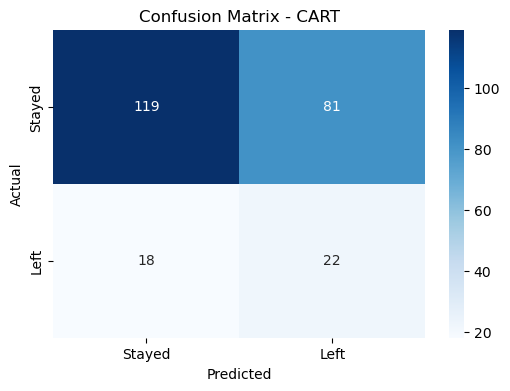

In [14]:
cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed", "Left"], yticklabels=["Stayed", "Left"])
plt.title("Confusion Matrix - CART")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 14. Visualize the decision tree
Each box shows the feature used for splitting, Gini impurity, number of records and predicted class.

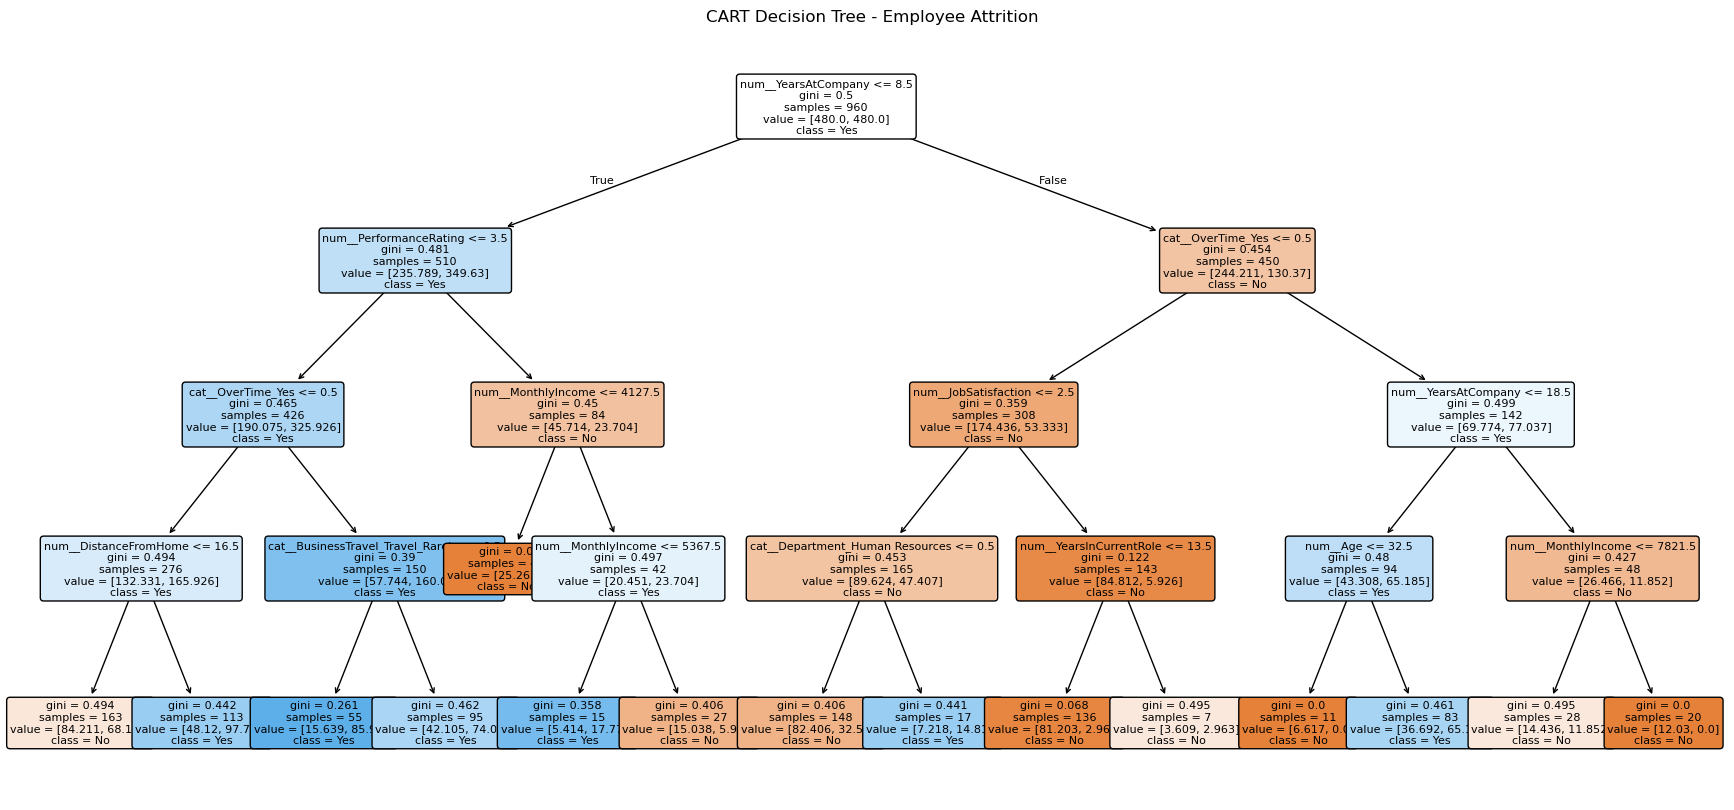

In [15]:
fitted_preprocessor = cart_model.named_steps["preprocessor"]
fitted_tree = cart_model.named_steps["classifier"]
feature_names = fitted_preprocessor.get_feature_names_out()

plt.figure(figsize=(22, 10))
plot_tree(fitted_tree, feature_names=feature_names,
          class_names=fitted_tree.classes_, filled=True,
          rounded=True, fontsize=8)
plt.title("CART Decision Tree - Employee Attrition")
plt.show()

## 15. Feature importance
This chart shows which employee details were most useful for the tree's splits. It does not prove that a feature causes an employee to leave.

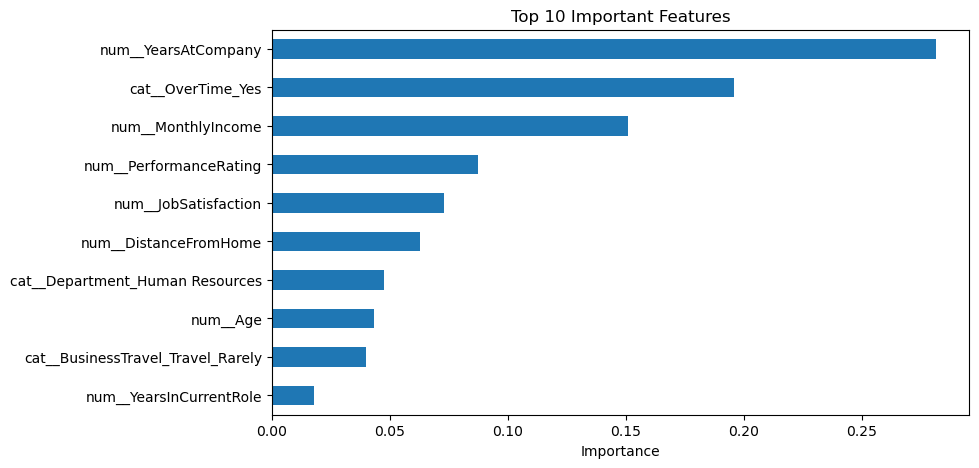

num__YearsAtCompany                  0.281536
cat__OverTime_Yes                    0.195959
num__MonthlyIncome                   0.150807
num__PerformanceRating               0.087429
num__JobSatisfaction                 0.072968
num__DistanceFromHome                0.062834
cat__Department_Human Resources      0.047476
num__Age                             0.043165
cat__BusinessTravel_Travel_Rarely    0.039953
num__YearsInCurrentRole              0.017872
dtype: float64

In [16]:
importance = pd.Series(fitted_tree.feature_importances_, index=feature_names)
importance = importance.sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.show()
display(importance)

## 16. Conclusion

 I used employee details to build an Employee Attrition Prediction model using CART. I explored the data, prepared numerical and categorical columns, split the dataset into training and testing parts, and trained the model using Gini impurity.

I evaluated the model using accuracy, precision, recall, F1-score and a confusion matrix. I also visualized the decision tree, checked feature importance and tested a new employee record.


